# Decision Tree: FARS Person-Level Data

## Scope and reproducibility

Predict **individual driver/passenger fatality** (`FATAL = 1` when `INJ_SEV = 4`) using only Tyson's 26 **pre-crash** fields (`BASE_COLS`). FARS includes fatal crashes: results estimate occupant fatality **conditional on FARS inclusion**, valid injury coding, occupant selection, and the numeric exclusions below. They do not estimate fatality risk for the general driving population or all crashes.

Tyson's loading, feature groups, label definition, occupant filter, and numeric-code exclusions are retained. The necessary preprocessing change is to **defer one-hot encoding until after the crash split, inside an sklearn Pipeline**; the encoder and numeric imputer are then refit in every training CV fold. No scaling is needed for trees. Impact/post-crash fields remain available in the original tier definitions but never enter a fitted model here. Iffat's notebook and the shared loader are unchanged.

### Load the data

Run this notebook from `project/` (or the repository root). Use Python 3.11+ and install `pandas`, `numpy`, `scikit-learn>=1.2`, `matplotlib`, `nbformat`, `nbclient`, and `ipykernel`. The environment versions are recorded below.

If the processed file is absent, download the official [2016 national CSV archive](https://static.nhtsa.gov/nhtsa/downloads/FARS/2016/National/FARS2016NationalCSV.zip), extract it to `project/data/FARS2016NationalCSV/`, then run **all cells** of the existing `load_fars_year.ipynb` with `YEAR=2016`, `SAVE_FORMAT="csv"`. Its validated person → vehicle → accident joins write `processed/fars_2016_person.csv`. The raw files and processed tables are gitignored.

For the execution accompanying this change, the archive SHA-256 was `44a452a25cb064bf680d4851ff3ad63d7e2d13704a58a1b287b4e02a7cebff0f`; the loader read 34,748 crashes, 52,714 vehicles, and 86,474 people. Reference: repository `data_dictionary.pdf`, NHTSA DOT HS 813 794, April 2026 ([official manual](https://rosap.ntl.bts.gov/view/dot/89797)). Use the **2016** code definitions, not only the newest year's definitions.

In [1]:
from pathlib import Path
import pandas as pd

YEAR = 2016
LOAD_FORMAT = "csv"   # "parquet" or "csv"
PROJECT_DIR = Path.cwd() if Path("decision_tree.ipynb").exists() else Path.cwd() / "project"
PROCESSED_DIR = PROJECT_DIR / "processed"
in_path = PROCESSED_DIR / f"fars_{YEAR}_person.{LOAD_FORMAT}"
if not in_path.exists():
    raise FileNotFoundError(f"Missing {in_path}. Run load_fars_year.ipynb as described above.")
if LOAD_FORMAT == "parquet":
    df = pd.read_parquet(in_path)
elif LOAD_FORMAT == "csv":
    df = pd.read_csv(in_path, low_memory=False)
else:
    raise ValueError('LOAD_FORMAT must be "parquet" or "csv"')
# This loader reads one year's archive. Older source files may omit YEAR.
if "YEAR" not in df:
    df["YEAR"] = YEAR
assert df["YEAR"].notna().all() and df["YEAR"].eq(YEAR).all(), "Unexpected/missing year"
print(f"Loaded {in_path.name}: {df.shape[0]:,} people x {df.shape[1]} columns")

Loaded fars_2016_person.csv: 86,474 people x 410 columns


In [2]:
ID_COLS = ["ST_CASE", "VEH_NO", "PER_NO", "YEAR", "STATE", "INJ_SEV"]  # key, split key, label source

BASE_COLS = [
    "AGE", "SEX", "PER_TYP", "SEAT_POS", "REST_USE", "BODY_TYP", "MOD_YEAR",
    "NUMOCCS", "TOW_VEH", "L_STATUS", "VSPD_LIM", "VALIGN", "VPROFILE",
    "VSURCOND", "VTRAFWAY", "VNUM_LAN", "VTRAFCON", "VTCONT_F", "HOUR",
    "DAY_WEEK", "MONTH", "RUR_URB", "FUNC_SYS", "LGT_COND", "WEATHER",
    "RELJCT2",
]
IMPACT_COLS = [
    "IMPACT1", "P_CRASH1", "P_CRASH2", "PCRASH4", "PCRASH5", "SPEEDREL",
    "DR_DRINK", "HARM_EV", "MAN_COLL", "REL_ROAD", "VE_FORMS", "PEDS",
    "PERNOTMVIT", "PERSONS", "PERMVIT", "DRUNK_DR",
]
POST_COLS = [
    "AIR_BAG", "EJECTION", "EXTRICAT", "ROLLOVER", "DEFORMED", "FIRE_EXP",
]

base_df             = df[ID_COLS + BASE_COLS]
base_impact_df      = df[ID_COLS + BASE_COLS + IMPACT_COLS]
base_impact_post_df = df[ID_COLS + BASE_COLS + IMPACT_COLS + POST_COLS]

In [3]:
print(f"BASE:               {len(BASE_COLS)} features")
print(f"BASE+IMPACT:        {len(BASE_COLS + IMPACT_COLS)} features")
print(f"BASE+IMPACT+POST:   {len(BASE_COLS + IMPACT_COLS + POST_COLS)} features")

BASE:               26 features
BASE+IMPACT:        42 features
BASE+IMPACT+POST:   48 features


In [4]:
FULL_SET = df[ID_COLS + BASE_COLS + IMPACT_COLS + POST_COLS].copy()

## PREPROCESSING STEP 1, Include binary output FATAL

In [5]:
# Keep only known injury levels 0-4 (drop other codes, including unknown/pre-crash deaths).
FULL_SET = FULL_SET.loc[FULL_SET["INJ_SEV"].between(0, 4)].copy()
FULL_SET["FATAL"] = (FULL_SET["INJ_SEV"] == 4).astype(int)
print(f"{len(FULL_SET):,} people remain")
FULL_SET["FATAL"].value_counts().sort_index()

84,823 people remain


FATAL
0    47017
1    37806
Name: count, dtype: int64

## PREPROCESS STEP 2, keep only vehicle occupants in dataset

In [6]:
# Keep Tyson's occupant definition: PER_TYP 1 = driver, 2 = passenger.
FULL_SET = FULL_SET.loc[FULL_SET["PER_TYP"].isin([1, 2])].copy()
print(f"{len(FULL_SET):,} people remain")

76,695 people remain


## PREPROCESS STEP 3, define encoding (fit after splitting)

Keep Tyson's numeric/categorical distinction. Unlike the original full-data `get_dummies`, the fitted vocabulary below uses training data only. Unknown FARS category **codes** remain explicit categories; an actual NaN gets a separate missing code. Unseen categories at validation/test time are ignored by the encoder. No injury label, person identifier, crash identifier, or higher-tier feature enters the transformer.

In [7]:
# True numbers; everything else is a category code. Definitions retained from Tyson.
NUMERIC_COLS = ["AGE", "MOD_YEAR", "NUMOCCS", "VSPD_LIM", "VE_FORMS",
                "PEDS", "PERNOTMVIT", "PERSONS", "PERMVIT"]
CATEGORICAL_COLS = [c for c in BASE_COLS + IMPACT_COLS + POST_COLS if c not in NUMERIC_COLS]
# Defer category casting/encoding: astype(int) on the full table fails on real NaNs.
# The Pipeline below handles NaNs and learns categories within training folds.

## PREPROCESS STEP 4, remove rows with unknown values in the numeric columns

Tyson's deterministic numeric-code exclusions are retained for a comparable initial cohort. The earlier rationale cited a 4.8% missing share; that is not assumed here: the following audit measures exclusions on the actual data.

**Concerns from the manual:** `VSPD_LIM=0` is a substantive no-limit/non-trafficway/driveway category, not an unknown value (PC7, p. 225). For 2016, `NUMOCCS=1..98` are actual counts and only `99` is unknown (V4, p. 110). The legacy rules below still exclude 97/98. Compare corrected handling in a separate experiment, coordinated with logistic regression. Complete-case selection can change the population and fatality prevalence; imputation also needs a sensitivity analysis. The remaining actual NaNs are handled using training-only medians for numeric fields and a fixed missing category for categorical fields.

In [8]:
# Tyson's existing exclusions, intentionally retained for this baseline.
UNKNOWN_CODES = {
    "AGE":      [998, 999],
    "MOD_YEAR": [9998, 9999],
    "NUMOCCS":  [97, 98, 99],  # legacy: 97/98 are valid counts in 2016
    "VSPD_LIM": [0, 98, 99],   # legacy: 0 is a substantive category, not unknown
}
cohort_before_numeric = FULL_SET.copy()
excluded_mask = pd.Series(False, index=FULL_SET.index)
exclusion_audit = []
for col, codes in UNKNOWN_CODES.items():
    mask = FULL_SET[col].isin(codes)
    exclusion_audit.append({"field": col, "matched_rows": int(mask.sum()),
                            "additional_excluded": int((mask & ~excluded_mask).sum())})
    excluded_mask |= mask
FULL_SET = FULL_SET.loc[~excluded_mask].copy()
print(f"{len(FULL_SET):,} people remain; {excluded_mask.sum():,} excluded by numeric codes")
display(pd.DataFrame(exclusion_audit))
display(pd.DataFrame({
    "occupants": [len(cohort_before_numeric), len(FULL_SET), int(excluded_mask.sum())],
    "fatal_share": [cohort_before_numeric.FATAL.mean(), FULL_SET.FATAL.mean(),
                    cohort_before_numeric.loc[excluded_mask, "FATAL"].mean()],
}, index=["before numeric exclusions", "retained", "excluded"]))

72,525 people remain; 4,170 excluded by numeric codes


,field,matched_rows,additional_excluded
0,AGE,1077,1077
1,MOD_YEAR,768,355
2,NUMOCCS,107,32
3,VSPD_LIM,2863,2706


,occupants,fatal_share
before numeric exclusions,76695,0.398149
retained,72525,0.401986
excluded,4170,0.331415


In [9]:
# Save the deterministic cohort; encoding/imputation are intentionally NOT fitted here.
RESULT_DIR = PROCESSED_DIR / "decision_tree"
RESULT_DIR.mkdir(parents=True, exist_ok=True)
out_path = RESULT_DIR / f"full_set_filtered_unscaled_{YEAR}.csv"
FULL_SET.to_csv(out_path, index=False)
print(f"Saved {out_path.name}: {FULL_SET.shape[0]:,} rows x {FULL_SET.shape[1]} columns")

Saved full_set_filtered_unscaled_2016.csv: 72,525 rows x 55 columns


In [10]:
# Model input lists now name raw fields; fitted one-hot names are obtained from the Pipeline.
# This replaces encoded_cols(), whose full-data vocabulary would see held-out categories.
BASE_FEATURES = BASE_COLS.copy()
BASE_IMPACT_FEATURES = BASE_COLS + IMPACT_COLS
BASE_IMPACT_POST_FEATURES = BASE_COLS + IMPACT_COLS + POST_COLS
print(f"BASE: {len(BASE_FEATURES)} raw fields (only these will be modeled)")

BASE: 26 raw fields (only these will be modeled)


## Data ready: raw tiers, then crash-grouped modeling

The following `base_df` retains IDs/label for bookkeeping, but `X` uses the explicit `BASE_FEATURES` whitelist. Higher tiers are reserved for future experiments.

In [11]:
# ML-ready, processed datasets: IDs + label + that tier's features
base_df             = FULL_SET[ID_COLS + ["FATAL"] + BASE_FEATURES]
base_impact_df      = FULL_SET[ID_COLS + ["FATAL"] + BASE_IMPACT_FEATURES]
base_impact_post_df = FULL_SET[ID_COLS + ["FATAL"] + BASE_IMPACT_POST_FEATURES]

## 1. Freeze a reproducible holdout by crash identity

Use one `GroupShuffleSplit(test_size=0.20, random_state=522)` with `(YEAR, STATE, ST_CASE)` as the group. **80/20 refers to unique crashes**; the occupant proportions can differ because crash sizes differ. We do not search for a favorable seed or stratify after seeing results. Sort person keys first for stable input order. Save a person-level split manifest so Iffat can reuse the exact cohort and split.

All choices below are fixed in advance: compare an unrestricted tree, a depth-4 tree, and a balanced depth-4 tree; tune only within training data; rank tuning candidates by grouped-CV average precision. Evaluate all prespecified comparisons once on the same holdout. Do not use the holdout to choose depth, class weight, features, or thresholds.

References: sklearn [GroupShuffleSplit](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GroupShuffleSplit.html) and [StratifiedGroupKFold](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedGroupKFold.html).

In [12]:
import hashlib
import platform
import numpy as np
import sklearn
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold, GridSearchCV, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, average_precision_score, confusion_matrix,
    ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay)

SEED = 522
CRASH_KEY = ["YEAR", "STATE", "ST_CASE"]
PERSON_KEY = CRASH_KEY + ["VEH_NO", "PER_NO"]
assert not base_df[PERSON_KEY].isna().any().any(), "Missing identity values"
assert not base_df.duplicated(PERSON_KEY).any(), "Duplicated person records"
model_df = base_df.sort_values(PERSON_KEY).reset_index(drop=True)
X = model_df[BASE_FEATURES].copy()
y = model_df["FATAL"].astype(int)
groups = pd.Series(pd.factorize(pd.MultiIndex.from_frame(model_df[CRASH_KEY]))[0], index=X.index)
assert set(X.columns) == set(BASE_COLS)
assert not (set(X.columns) & set(ID_COLS + ["FATAL"] + IMPACT_COLS + POST_COLS))
assert set(y.unique()) == {0, 1}
assert not np.isinf(X.to_numpy(dtype=float)).any()

splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
train_idx, test_idx = next(splitter.split(X, y, groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
g_train, g_test = groups.iloc[train_idx], groups.iloc[test_idx]
assert set(g_train).isdisjoint(set(g_test)), "Crash leakage"
assert g_test.nunique() == int(np.ceil(0.20 * groups.nunique()))
assert len(train_idx) + len(test_idx) == len(model_df)
assert set(y_train.unique()) == set(y_test.unique()) == {0, 1}

manifest = model_df[PERSON_KEY + ["FATAL"]].copy()
manifest["split"] = "train"
manifest.loc[test_idx, "split"] = "test"
manifest.to_csv(RESULT_DIR / f"precrash_split_{YEAR}_seed{SEED}.csv", index=False)
assert manifest.groupby(CRASH_KEY)["split"].nunique().max() == 1

def split_summary(label, target, crash_groups):
    return {"split": label, "occupants": len(target), "crashes": crash_groups.nunique(),
            "nonfatal": int((target == 0).sum()), "fatal": int(target.sum()),
            "fatal_share": target.mean()}
split_table = pd.DataFrame([split_summary("train", y_train, g_train),
                            split_summary("test", y_test, g_test)]).set_index("split")
display(split_table)
print(f"Test share: {len(y_test)/len(y):.2%} of occupants; {g_test.nunique()/groups.nunique():.2%} of crashes")
print("Overlapping crashes:", len(set(g_train) & set(g_test)))
print({"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__,
       "sklearn": sklearn.__version__, "matplotlib": matplotlib.__version__})
with in_path.open("rb") as f:
    print("Processed input SHA-256:", hashlib.file_digest(f, "sha256").hexdigest())

,occupants,crashes,nonfatal,fatal,fatal_share
split,,,,,
train,57864,26158,34524,23340,0.403360
test,14661,6540,8847,5814,0.396562


Test share: 20.22% of occupants; 20.00% of crashes
Overlapping crashes: 0
{'python': '3.14.8', 'pandas': '3.1.0', 'numpy': '2.5.4', 'sklearn': '1.9.1', 'matplotlib': '3.11.2'}
Processed input SHA-256: b5acdab17d8bb6c4bceefc29e415299f024f2e60a9158c92da876db085bf8487


## 2. Class imbalance and train-only preprocessing

Inspect the counts above; accuracy alone can reward the majority class. Include a majority-class dummy reference, balanced accuracy (mean recall across the two classes), and positive-class precision/recall/F1 for **fatality = 1**. `class_weight="balanced"` uses inverse training class frequencies; it changes split/leaf weighting rather than resampling or altering the holdout. Compare it to the same depth-4 tree with no weights.

Retain numeric units. Fit median imputation (plus missing indicators) only on each training fold. Categorical FARS codes—including unknown/not-reported codes—are nominal; replace actual NaNs with `-1`, then one-hot encode. Unseen holdout codes become all-zero indicators for that field. Missingness/unknown codes can reflect differential reporting by severity; their predictive value must be interpreted cautiously.

In [13]:
BASE_NUMERIC = [c for c in BASE_FEATURES if c in NUMERIC_COLS]
BASE_CATEGORICAL = [c for c in BASE_FEATURES if c not in NUMERIC_COLS]
display(X_train.isna().sum().rename("training_actual_NaNs").to_frame().T)

def make_tree(**params):
    preprocess = ColumnTransformer([
        ("numeric", Pipeline([
            ("impute", SimpleImputer(strategy="median", add_indicator=True, keep_empty_features=True)),
        ]), BASE_NUMERIC),
        ("categorical", Pipeline([
            ("impute", SimpleImputer(strategy="constant", fill_value=-1, keep_empty_features=True)),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=True)),
        ]), BASE_CATEGORICAL),
    ])
    return Pipeline([("preprocess", preprocess),
                     ("tree", DecisionTreeClassifier(random_state=SEED, **params))])

candidates = {
    "Unrestricted": make_tree(),
    "Depth 4": make_tree(max_depth=4),
    "Depth 4 balanced": make_tree(max_depth=4, class_weight="balanced"),
}
# No use of X_test/y_test in model fitting, CV scoring, or selection below.
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_splits = list(cv.split(X_train, y_train, groups=g_train))
fold_audit = []
for fold, (fit_idx, valid_idx) in enumerate(cv_splits, 1):
    assert set(g_train.iloc[fit_idx]).isdisjoint(set(g_train.iloc[valid_idx]))
    assert set(y_train.iloc[fit_idx].unique()) == set(y_train.iloc[valid_idx].unique()) == {0, 1}
    fold_audit.append({"fold": fold, "fit_crashes": g_train.iloc[fit_idx].nunique(),
                       "validation_crashes": g_train.iloc[valid_idx].nunique(),
                       "validation_fatal_share": y_train.iloc[valid_idx].mean()})
display(pd.DataFrame(fold_audit))
scoring = {"ap": "average_precision", "balanced_accuracy": "balanced_accuracy",
           "roc_auc": "roc_auc", "f1": "f1"}
cv_rows = []
for name, model in candidates.items():
    scores = cross_validate(model, X_train, y_train, cv=cv_splits, scoring=scoring,
                            return_train_score=True, n_jobs=2, error_score="raise")
    row = {"model": name}
    for metric in scoring:
        row[f"train_{metric}"] = scores[f"train_{metric}"].mean()
        row[f"cv_{metric}"] = scores[f"test_{metric}"].mean()
        row[f"cv_{metric}_sd"] = scores[f"test_{metric}"].std(ddof=1)
    cv_rows.append(row)
cv_comparison = pd.DataFrame(cv_rows).set_index("model")
display(cv_comparison.round(4))

,AGE,SEX,PER_TYP,SEAT_POS,REST_USE,BODY_TYP,MOD_YEAR,NUMOCCS,TOW_VEH,L_STATUS,...,VTRAFCON,VTCONT_F,HOUR,DAY_WEEK,MONTH,RUR_URB,FUNC_SYS,LGT_COND,WEATHER,RELJCT2
training_actual_NaNs,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


,fold,fit_crashes,validation_crashes,validation_fatal_share
0,1,20829,5329,0.403353
1,2,20874,5284,0.403387
2,3,20901,5257,0.403353
3,4,20980,5178,0.403283
4,5,21048,5110,0.403422


,train_ap,cv_ap,cv_ap_sd,train_balanced_accuracy,cv_balanced_accuracy,cv_balanced_accuracy_sd,train_roc_auc,cv_roc_auc,cv_roc_auc_sd,train_f1,cv_f1,cv_f1_sd
model,,,,,,,,,,,,
Unrestricted,1.0000,0.5417,0.0050,0.9996,0.6863,0.0044,1.0000,0.6862,0.0044,0.9996,0.6272,0.0045
Depth 4,0.7239,0.7212,0.0011,0.7197,0.7181,0.0033,0.7921,0.7890,0.0015,0.6500,0.6480,0.0080
Depth 4 balanced,0.7220,0.7205,0.0026,0.7239,0.7219,0.0026,0.7928,0.7913,0.0024,0.6657,0.6634,0.0076


## 3. Tune exclusively within grouped training CV

Use the same five crash-disjoint folds for every candidate. `StratifiedGroupKFold` approximates class balance while retaining entire crashes. Grid search varies depth, minimum leaf size, cost-complexity pruning (`ccp_alpha`), and class weighting. The primary selection metric is **average precision (AP)**, a step-weighted summary of the precision–recall curve; we report it as **PR-AUC (AP)**, not trapezoidal PR area. AP's no-skill reference is positive prevalence. Fold standard deviations describe variability, not independent-sample confidence intervals; occupants within a crash are dependent.

The grid and selection metric are fixed before holdout evaluation. `refit="ap"` fits the winning pipeline on all training data. Tuning scores can be optimistic from trying multiple settings; the untouched holdout is the final check.

Metric reference: sklearn [average_precision_score](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html).

In [14]:
param_grid = {
    "tree__max_depth": [4, 8, None],
    "tree__min_samples_leaf": [20, 100],
    "tree__ccp_alpha": [0.0, 0.001],
    "tree__class_weight": [None, "balanced"],
}
search = GridSearchCV(make_tree(), param_grid, scoring=scoring, refit="ap",
                      cv=cv_splits, n_jobs=2, error_score="raise", return_train_score=True)
search.fit(X_train, y_train)
cv_results = pd.DataFrame(search.cv_results_).sort_values("rank_test_ap")
display(cv_results[["params", "mean_train_ap", "mean_test_ap", "std_test_ap",
                    "mean_test_balanced_accuracy", "mean_test_roc_auc", "mean_test_f1"]].head(10))
print("Best training-CV parameters:", search.best_params_)
print(f"Best mean CV AP: {search.best_score_:.4f}")
cv_results.to_csv(RESULT_DIR / f"precrash_cv_{YEAR}.csv", index=False)

fitted_models = {}
for name, model in candidates.items():
    fitted_models[name] = model.fit(X_train, y_train)
fitted_models["Tuned (CV AP)"] = search.best_estimator_
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
# Freeze the model choice here, before examining holdout scores.
selected_name = "Tuned (CV AP)"
selected_model = fitted_models[selected_name]

,params,mean_train_ap,mean_test_ap,std_test_ap,mean_test_balanced_accuracy,mean_test_roc_auc,mean_test_f1
5,"{'tree__ccp_alpha': 0.0, 'tree__class_weight':...",0.810084,0.786259,0.005539,0.737727,0.824911,0.674581
11,"{'tree__ccp_alpha': 0.0, 'tree__class_weight':...",0.810314,0.785730,0.005567,0.744834,0.824337,0.698725
3,"{'tree__ccp_alpha': 0.0, 'tree__class_weight':...",0.789061,0.778257,0.003483,0.736216,0.823056,0.671897
9,"{'tree__ccp_alpha': 0.0, 'tree__class_weight':...",0.788480,0.777482,0.004524,0.745068,0.823119,0.698339
2,"{'tree__ccp_alpha': 0.0, 'tree__class_weight':...",0.789224,0.771421,0.005543,0.737980,0.821503,0.674632
8,"{'tree__ccp_alpha': 0.0, 'tree__class_weight':...",0.784503,0.768787,0.005947,0.746678,0.821732,0.700937
4,"{'tree__ccp_alpha': 0.0, 'tree__class_weight':...",0.856571,0.765669,0.005783,0.730236,0.808235,0.669209
10,"{'tree__ccp_alpha': 0.0, 'tree__class_weight':...",0.857305,0.764212,0.006072,0.728268,0.806843,0.680761
20,"{'tree__ccp_alpha': 0.001, 'tree__class_weight...",0.736175,0.733810,0.003371,0.729536,0.802299,0.677289
21,"{'tree__ccp_alpha': 0.001, 'tree__class_weight...",0.736175,0.733810,0.003371,0.729536,0.802299,0.677289


Best training-CV parameters: {'tree__ccp_alpha': 0.0, 'tree__class_weight': None, 'tree__max_depth': None, 'tree__min_samples_leaf': 100}
Best mean CV AP: 0.7863


## 4. Final holdout evaluation

Use each model's default `predict` decision rule (binary probability threshold approximately 0.5; ties follow sklearn's class ordering). Report occupant-level metrics on the **same** holdout: accuracy, balanced accuracy, precision, recall, F1, ROC-AUC, and PR-AUC (AP). ROC/AP use fatal-class probabilities, not hard labels. Unrestricted trees often produce near-binary leaf probabilities, which can limit ranking quality. No threshold tuning or probability calibration is performed here; weighted tree probabilities are not automatically calibrated risks.

Confusion matrices use **rows = actual**, **columns = predicted**, order `[nonfatal, fatal]`: `[[TN, FP], [FN, TP]]`. Test comparisons are descriptive; retain the CV-selected model even if another candidate happens to score higher on this holdout.

,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,pr_auc_ap,TN,FP,FN,TP
model,,,,,,,,,,,
Majority dummy,0.6034,0.5000,0.0000,0.0000,0.0000,0.5000,0.3966,8847,0,5814,0
Unrestricted,0.6979,0.6872,0.6153,0.6355,0.6253,0.6872,0.5356,6537,2310,2119,3695
Depth 4,0.7512,0.7250,0.7261,0.5982,0.6560,0.7915,0.7221,7535,1312,2336,3478
Depth 4 balanced,0.7435,0.7273,0.6869,0.6490,0.6674,0.7902,0.7180,7127,1720,2041,3773
Tuned (CV AP),0.7676,0.7426,0.7494,0.6219,0.6798,0.8332,0.7921,7638,1209,2198,3616


Holdout prevalence / no-skill AP reference: 0.3966
Selected using training CV only: Tuned (CV AP)


,depth,leaves,train_accuracy
model,,,
Unrestricted,50,11330,0.999706
Depth 4,4,16,0.744556
Depth 4 balanced,4,16,0.739907
Tuned (CV AP),18,431,0.774298


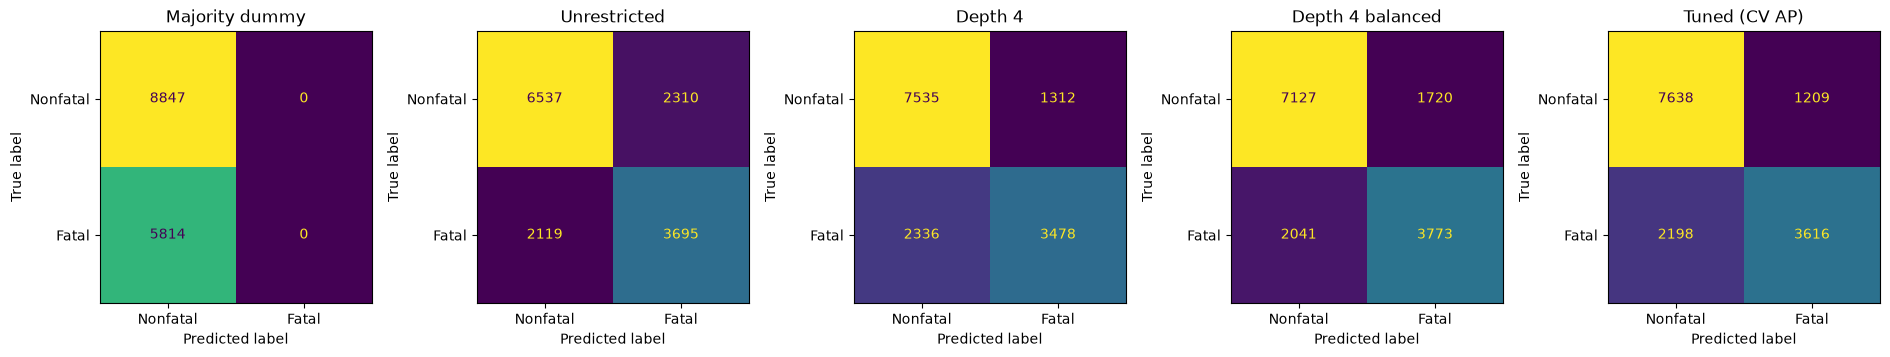

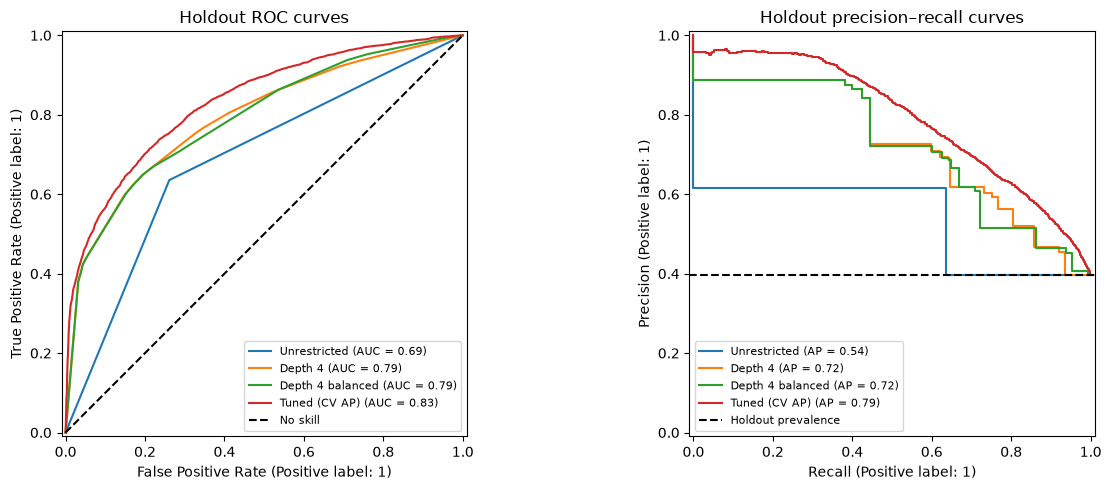

In [15]:
def evaluate(name, model):
    pred = model.predict(X_test)
    positive_index = list(model.classes_).index(1)
    score = model.predict_proba(X_test)[:, positive_index]
    cm = confusion_matrix(y_test, pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    return {"model": name, "accuracy": accuracy_score(y_test, pred),
            "balanced_accuracy": balanced_accuracy_score(y_test, pred),
            "precision": precision_score(y_test, pred, zero_division=0),
            "recall": recall_score(y_test, pred, zero_division=0),
            "f1": f1_score(y_test, pred, zero_division=0),
            "roc_auc": roc_auc_score(y_test, score),
            "pr_auc_ap": average_precision_score(y_test, score),
            "TN": tn, "FP": fp, "FN": fn, "TP": tp}, pred, score

all_models = {"Majority dummy": dummy, **fitted_models}
rows, predictions, probabilities = [], {}, {}
for name, model in all_models.items():
    row, predictions[name], probabilities[name] = evaluate(name, model)
    rows.append(row)
test_results = pd.DataFrame(rows).set_index("model")
display(test_results.round(4))
test_results.to_csv(RESULT_DIR / f"precrash_test_metrics_{YEAR}.csv")
print(f"Holdout prevalence / no-skill AP reference: {y_test.mean():.4f}")
print("Selected using training CV only:", selected_name)
complexity = pd.DataFrame([
    {"model": name, "depth": model.named_steps["tree"].get_depth(),
     "leaves": model.named_steps["tree"].get_n_leaves(),
     "train_accuracy": model.score(X_train, y_train)}
    for name, model in fitted_models.items()
]).set_index("model")
display(complexity)

fig, axes = plt.subplots(1, len(all_models), figsize=(19, 3.7))
for ax, name in zip(axes, all_models):
    ConfusionMatrixDisplay.from_predictions(y_test, predictions[name], labels=[0, 1],
        display_labels=["Nonfatal", "Fatal"], ax=ax, colorbar=False, values_format="d")
    ax.set_title(name)
fig.tight_layout()
plt.show()
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name in fitted_models:
    RocCurveDisplay.from_predictions(y_test, probabilities[name], name=name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_test, probabilities[name], name=name, ax=axes[1])
axes[0].plot([0, 1], [0, 1], "k--", label="No skill")
axes[1].axhline(y_test.mean(), color="black", linestyle="--", label="Holdout prevalence")
axes[0].legend(fontsize=8)
axes[1].legend(fontsize=8)
axes[0].set_title("Holdout ROC curves")
axes[1].set_title("Holdout precision–recall curves")
fig.tight_layout()
plt.show()

## 5. Visualize the tree and feature importances

Plot the prespecified depth-4 model; show the first three split levels for legibility (ellipsis nodes indicate hidden branches). Node values are proportions; sample counts refer to training occupants. One-hot splits at 0.5 separate presence/absence of that category. The complete fitted tree remains available in `fitted_models["Depth 4"]`.

For the CV-selected model, show impurity-based importances both by encoded column and summed back to original fields. These use the fitted training model only. Impurity importance favors variables with more possible splits/categories and can divide credit between correlated predictors. It measures model reliance, **not causation** or a seatbelt intervention effect. A low importance does not establish that a field is uninformative. Test data are not used to select the displayed variables.

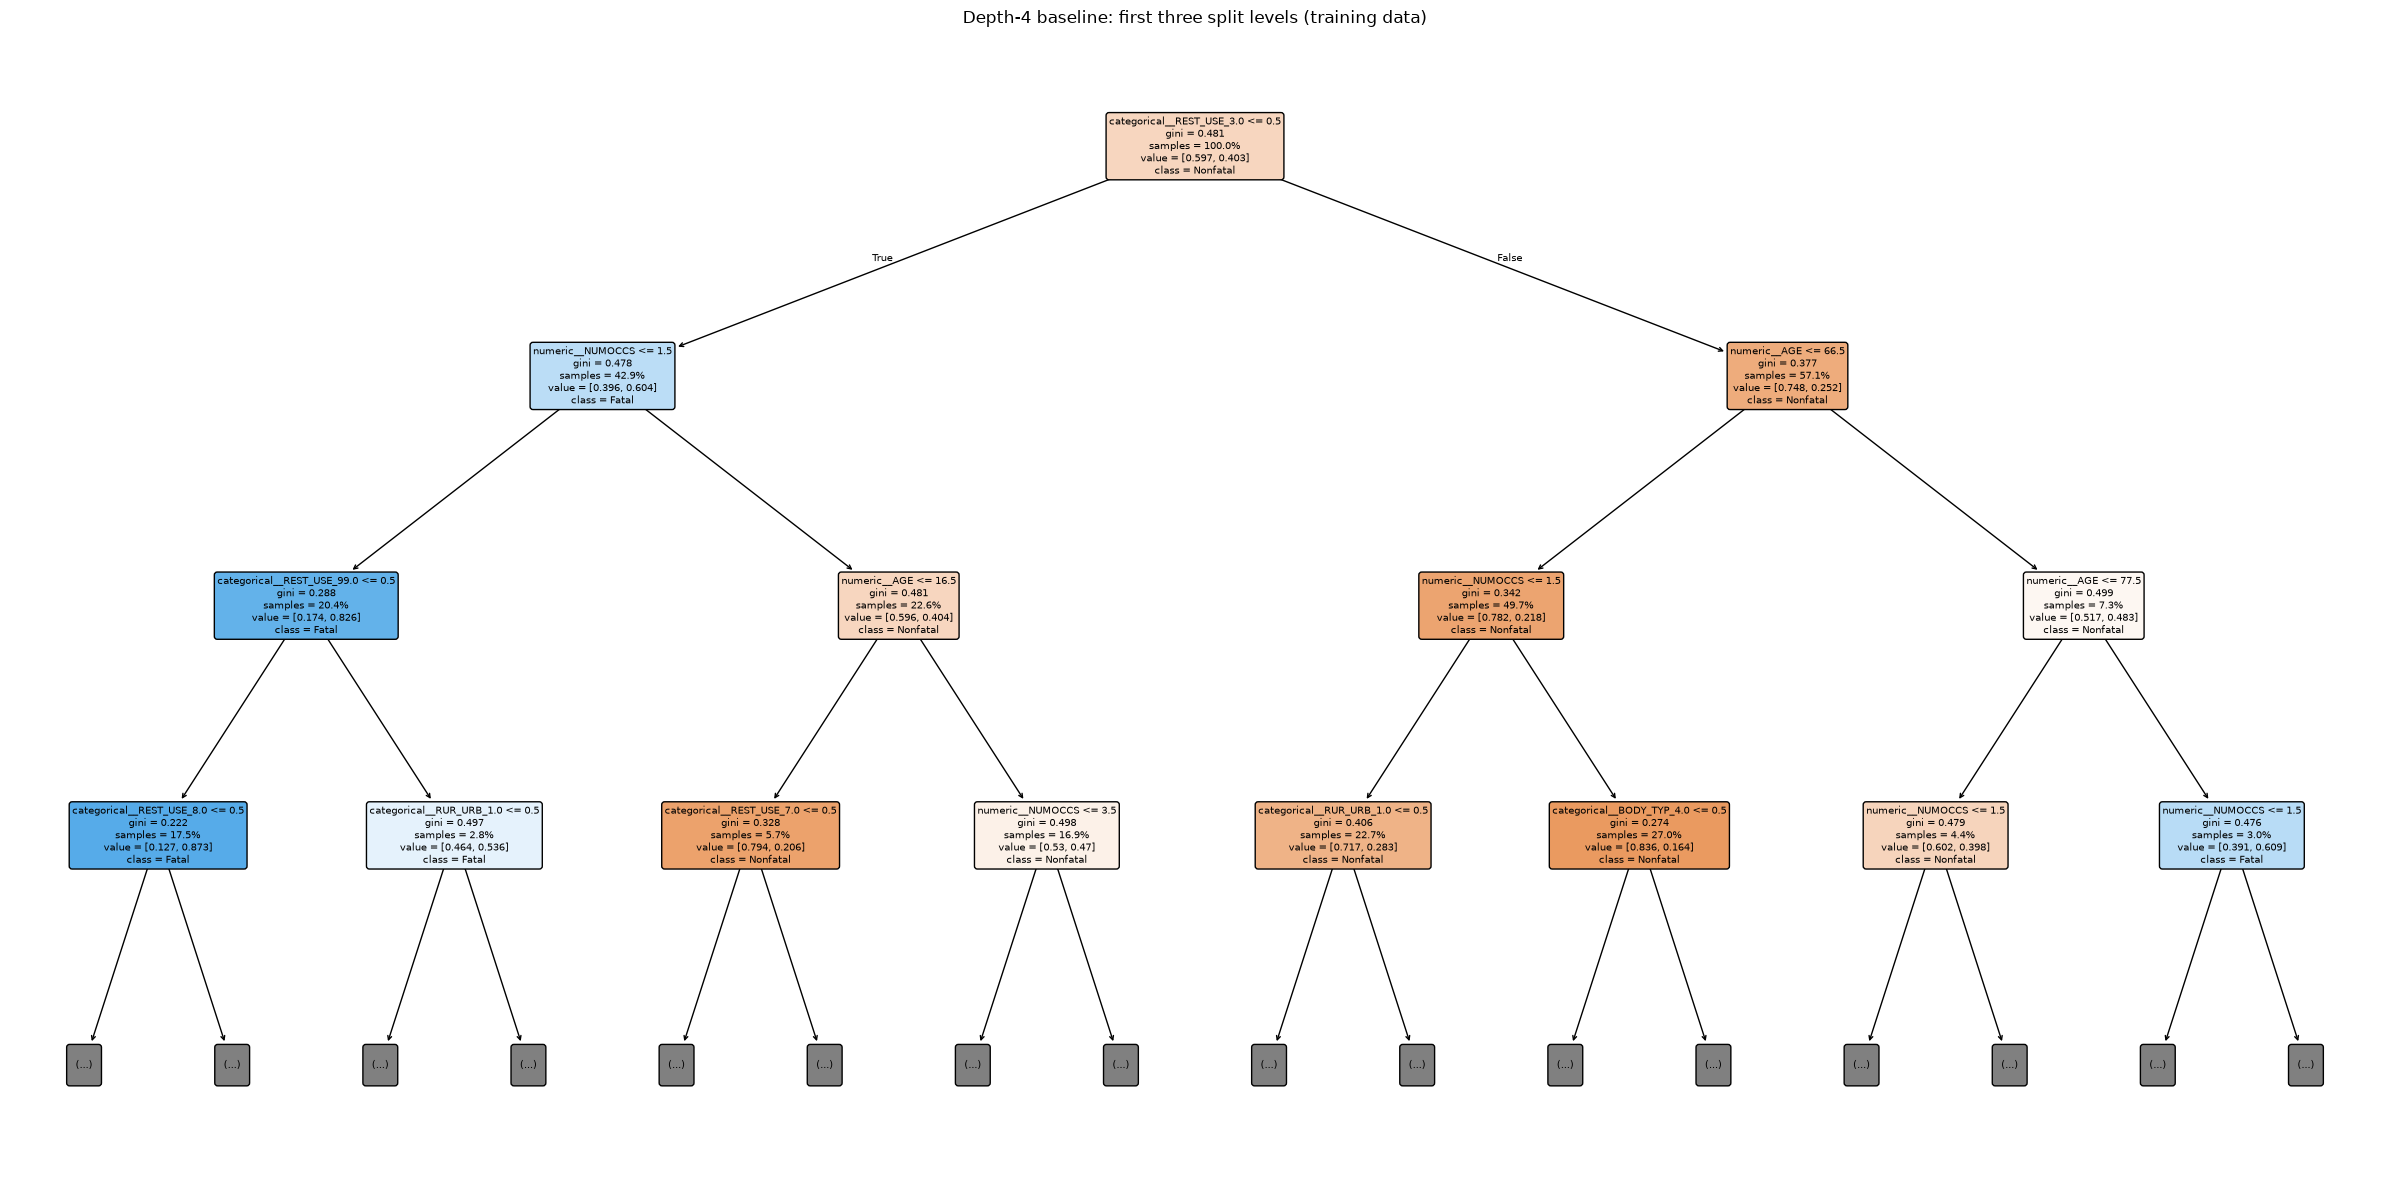

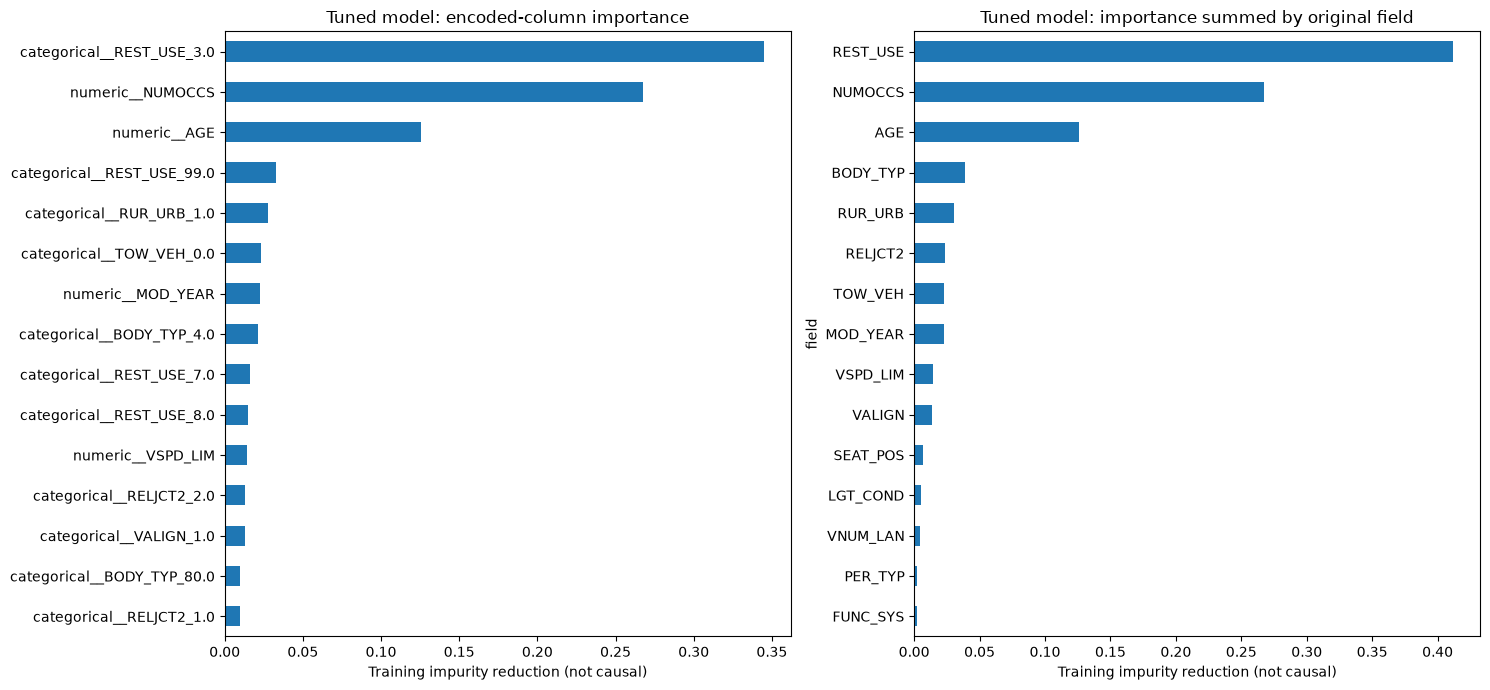

,importance
field,
REST_USE,0.411779
NUMOCCS,0.267269
AGE,0.125733
BODY_TYP,0.038572
RUR_URB,0.030060
RELJCT2,0.023477
TOW_VEH,0.022939
MOD_YEAR,0.022671
VSPD_LIM,0.014074


In [16]:
view_model = fitted_models["Depth 4"]
view_names = view_model.named_steps["preprocess"].get_feature_names_out()
fig, ax = plt.subplots(figsize=(24, 12))
plot_tree(view_model.named_steps["tree"], feature_names=view_names,
          class_names=["Nonfatal", "Fatal"], filled=True, rounded=True,
          proportion=True, max_depth=3, fontsize=7, ax=ax)
ax.set_title("Depth-4 baseline: first three split levels (training data)")
fig.tight_layout()
plt.show()

feature_names = selected_model.named_steps["preprocess"].get_feature_names_out()
importances = pd.Series(selected_model.named_steps["tree"].feature_importances_,
                        index=feature_names, name="importance").sort_values(ascending=False)

def original_field(encoded):
    name = encoded.split("__", 1)[1]
    matches = [c for c in BASE_FEATURES
               if name == c or name.startswith(c + "_") or name == "missingindicator_" + c]
    assert len(matches) == 1, (encoded, matches)
    return matches[0]

importance_table = importances.rename_axis("encoded_feature").reset_index()
importance_table["field"] = importance_table["encoded_feature"].map(original_field)
grouped_importance = importance_table.groupby("field")["importance"].sum().sort_values(ascending=False)
assert np.isclose(importances.sum(), grouped_importance.sum())
fig, axes = plt.subplots(1, 2, figsize=(15, 7))
importances.head(15).sort_values().plot.barh(ax=axes[0])
grouped_importance.head(15).sort_values().plot.barh(ax=axes[1])
axes[0].set_title("Tuned model: encoded-column importance")
axes[1].set_title("Tuned model: importance summed by original field")
for ax in axes:
    ax.set_xlabel("Training impurity reduction (not causal)")
fig.tight_layout()
plt.show()
display(grouped_importance.to_frame())
importance_table.to_csv(RESULT_DIR / f"precrash_importances_{YEAR}.csv", index=False)

## 6. Medium-truck investigation (descriptive only)

The repository's NHTSA manual, Appendix C **Vehicle Classification by NCSA Data Elements**, pp. C-29–C-30, assigns **medium trucks = BODY_TYP in {60, 61, 62, 64, 67, 71}** for 1991 onward. Code 67 (medium/heavy pickup) is included as medium by the classification convention. This is a category definition, not a claim that every vehicle's exact GVWR is known. The heavy-truck category includes 63, 66, 72, 78, and conditionally 79 with `TOW_VEH` in 1–4; `60..79` would incorrectly conflate categories. Review year-specific body-type labels and any VIN/GVWR definitions before changing the project population.

The audit below counts both occupants and unique vehicles because person-level rows otherwise overcount trucks with multiple occupants. It does **not** add a new predictor or filter the modeling cohort. `BODY_TYP` is already one of the base categorical fields. These counts refer to the retained cohort, not national truck totals.

In [17]:
MEDIUM_TRUCK_BODY_TYPES = {60, 61, 62, 64, 67, 71}
assert YEAR >= 1991, "Review historical BODY_TYP classification before using these codes"
medium = model_df.loc[model_df["BODY_TYP"].isin(MEDIUM_TRUCK_BODY_TYPES)]
truck_audit = medium.groupby("BODY_TYP").size().rename("retained_occupants").to_frame()
vehicle_counts = medium.drop_duplicates(CRASH_KEY + ["VEH_NO"]).groupby("BODY_TYP").size()
truck_audit["unique_vehicles"] = vehicle_counts
print(f"Medium-truck occupants: {len(medium):,}; unique vehicles: {len(medium.drop_duplicates(CRASH_KEY + ['VEH_NO'])):,}")
display(truck_audit)

Medium-truck occupants: 1,492; unique vehicles: 1,078


,retained_occupants,unique_vehicles
BODY_TYP,,
60.0,6,6
61.0,427,315
62.0,215,167
64.0,290,228
67.0,541,351
71.0,13,11


## 7. Interpretation, limitations, and next experiments

- **Temporal availability:** “pre-crash” describes the underlying circumstance, not necessarily information available to a live system. `REST_USE` represents restraint/helmet use at the time of the crash but is reconstructed afterward; unknown use may be related to injury severity. `BODY_TYP` mixes vehicle types, so restraint/helmet categories must be interpreted within vehicle type. `NUMOCCS`, `L_STATUS`, and police-coded roadway fields also need an availability audit for the intended deployment setting.
- **Alcohol and later stages:** `DR_DRINK`/`DRUNK_DR` remain excluded with the impact group. Alcohol can precede the crash physically, but police determinations, testing, missingness and BAC imputations can use information collected after the outcome. Review the exact code/source/timing before moving any alcohol variable into the base tier. Conversely `P_CRASH*` fields may describe pre-impact conditions; Tyson's groups are a working convention, not a final timing taxonomy. Airbag deployment, ejection, extrication, rollover, deformation and fire describe crash consequences and do not belong in this baseline. `INJ_SEV` is the label source only.
- **Preprocessing audit:** full-data one-hot vocabulary is removed from this notebook. The logistic-regression notebook currently fits `StandardScaler` before a split and uses full-data dummies; discuss a training-only Pipeline with Iffat without modifying her notebook here. Share the saved split manifest, cohort, features and metric definitions for a fair comparison. Match the cohort before reusing person IDs: another missing-data policy can change it.
- **Selection/reporting bias:** numeric-code row deletion can shift prevalence; actual NaNs and special categorical codes have different meanings. Correct `NUMOCCS` and `VSPD_LIM=0` handling in a coordinated sensitivity experiment. Do not pool all category codes into generic “missing.” Driver/passenger selection can exclude other person types, including some occupants; verify that this matches the proposal. FARS inclusion itself depends on a crash fatality, so conditioning on it can induce associations and limits external validity. Performance is conditional on these choices, not a population crash-fatality estimate.
- **Evaluation limits:** the holdout separates crashes but not states, years, vehicle makes, or reporting practices. Scores weight occupants equally, so larger crashes contribute more. Do not interpret CV SDs as confidence intervals. If uncertainty estimates are needed, resample whole crashes, not occupants. Tree leaf probabilities are not calibrated automatically, particularly after class weighting.
- **Recommended next experiment:** first align logistic regression and tree on the same crash split and training-only transforms. Then prespecify a restraint-use/unknown-code ablation and a corrected-missingness sensitivity analysis, selecting by training CV. For future pre-crash → impact → post-crash comparisons, freeze the person cohort and crash folds, document the information time of each new variable, and use a fresh year or new locked holdout for confirmatory claims after today's results have been inspected. Consider a later-year holdout to assess temporal generalization. Calibration or decision-threshold selection must use grouped training validation only.

The result summary below is generated from this run's actual metrics, not manually supplied performance numbers.

In [18]:
chosen = test_results.loc[selected_name]
unrestricted = test_results.loc["Unrestricted"]
limited = test_results.loc["Depth 4"]
weighted = test_results.loc["Depth 4 balanced"]
top_fields = ", ".join(grouped_importance.head(5).index)
display(Markdown(f"""**Executed result:** {len(y):,} retained occupants from {groups.nunique():,} crashes; """
    f"holdout has {len(y_test):,} occupants and {g_test.nunique():,} crashes, with no crash overlap. "
    f"The training-CV-selected tree achieved holdout accuracy **{chosen['accuracy']:.3f}**, "
    f"balanced accuracy **{chosen['balanced_accuracy']:.3f}**, precision **{chosen['precision']:.3f}**, "
    f"recall **{chosen['recall']:.3f}**, F1 **{chosen['f1']:.3f}**, ROC-AUC **{chosen['roc_auc']:.3f}**, "
    f"and PR-AUC (AP) **{chosen['pr_auc_ap']:.3f}** (prevalence reference {y_test.mean():.3f}).\n\n"
    f"Unrestricted versus depth-4 test balanced accuracy: {unrestricted['balanced_accuracy']:.3f} versus "
    f"{limited['balanced_accuracy']:.3f}; AP: {unrestricted['pr_auc_ap']:.3f} versus {limited['pr_auc_ap']:.3f}. "
    f"Depth-4 fatal recall with/without balancing: {weighted['recall']:.3f}/{limited['recall']:.3f}; "
    f"precision: {weighted['precision']:.3f}/{limited['precision']:.3f}. "
    f"Inspect the train/CV gap and leaf counts above for overfitting.\n\n"
    f"Largest summed training impurity importances: **{top_fields}**. These are associations learned "
    f"within the selected FARS cohort, not evidence of causal effects."))
assert all(not (set(model.named_steps['preprocess'].feature_names_in_) &
                set(ID_COLS + ['FATAL'] + IMPACT_COLS + POST_COLS))
           for model in fitted_models.values())
print("Completed: crash-disjoint holdout and CV assertions; base-only feature assertions; all requested metrics.")

**Executed result:** 72,525 retained occupants from 32,698 crashes; holdout has 14,661 occupants and 6,540 crashes, with no crash overlap. The training-CV-selected tree achieved holdout accuracy **0.768**, balanced accuracy **0.743**, precision **0.749**, recall **0.622**, F1 **0.680**, ROC-AUC **0.833**, and PR-AUC (AP) **0.792** (prevalence reference 0.397).

Unrestricted versus depth-4 test balanced accuracy: 0.687 versus 0.725; AP: 0.536 versus 0.722. Depth-4 fatal recall with/without balancing: 0.649/0.598; precision: 0.687/0.726. Inspect the train/CV gap and leaf counts above for overfitting.

Largest summed training impurity importances: **REST_USE, NUMOCCS, AGE, BODY_TYP, RUR_URB**. These are associations learned within the selected FARS cohort, not evidence of causal effects.

Completed: crash-disjoint holdout and CV assertions; base-only feature assertions; all requested metrics.
